In [2]:
# reading data from OPS and DustTrak during the YSF June 2025 iFireNet experiment

# imports 
import os
import datetime as dt
import scipy.io
import numpy as np  
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import re
import shapely.geometry
from shapely.geometry import Point, Polygon
import geopandas as gpd

# Establish the project directory
try:
    proj_dir = os.path.dirname(os.path.abspath(__file__))  # get the project directory
except NameError:
    proj_dir = os.getcwd()  # fallback if __file__ is not defined

First lets work on reading OPS data. 

In [3]:
# reading data from OPS and DustTrak
def read_ops(csv_file_path):
    """ Reads the OPS data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the OPS file.
        df (pd.DataFrame): DataFrame containing the OPS data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:37]  # first 37 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    bin_cut_points = {}
    for line in metadata:
        key, value = line.strip().split(',', 1)
        match = re.match(r'Bin (\d+) Cut Point \(um\)', key)
        if match:
            bin_number = int(match.group(1))
            bin_cut_points[bin_number] = float(value)
        else:
            metadata_dict[key.strip()] = value.strip()
    metadata_dict['Bin Cut Points'] = bin_cut_points

    df = pd.read_csv(csv_file_path, skiprows=37) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%Y/%m/%d %H:%M:%S"
        )
    print(f"Start datetime: {start_datetime}")
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')

    return [metadata_dict, df]

# TEST: Read OPS data
# path to the csv file
csv_file_path = os.path.join(proj_dir, 'data/OPS/2000_01_01-07_58_02-TEST_001.csv')
data = read_ops(csv_file_path)


Start datetime: 2000-01-01 07:58:02


In [4]:
data[1].columns
for b in data[0]['Bin Cut Points'].keys():
    print(f"Bin {b} Cut Point (um): {data[0]['Bin Cut Points'][b]}")


Bin 1 Cut Point (um): 0.3
Bin 2 Cut Point (um): 0.374
Bin 3 Cut Point (um): 0.465
Bin 4 Cut Point (um): 0.579
Bin 5 Cut Point (um): 0.721
Bin 6 Cut Point (um): 0.897
Bin 7 Cut Point (um): 1.117
Bin 8 Cut Point (um): 1.391
Bin 9 Cut Point (um): 1.732
Bin 10 Cut Point (um): 2.156
Bin 11 Cut Point (um): 2.685
Bin 12 Cut Point (um): 3.343
Bin 13 Cut Point (um): 4.162
Bin 14 Cut Point (um): 5.182
Bin 15 Cut Point (um): 6.451
Bin 16 Cut Point (um): 8.031
Bin 17 Cut Point (um): 10.0


In [5]:
ops_1_file = os.path.join(proj_dir, 'data/OPS/2000_01_01-07_58_02-TEST_001.csv')     # Won't use this file. Too few data points.
ops_2_file = os.path.join(proj_dir, 'data/OPS/2025_06_09-08_39_19-TEST_002.csv')
ops_3_file = os.path.join(proj_dir, 'data/OPS/2025_06_10-07_55_53-TEST_001.csv')

ops_1 = read_ops(ops_1_file)
ops_2 = read_ops(ops_2_file)
ops_3 = read_ops(ops_3_file)

# trim first 10 minutes of day 2 and day 3 data
ops_2[1] = ops_2[1][ops_2[1]['datetime'] >= ops_2[1]['datetime'].min() + pd.Timedelta(minutes=10)]
ops_3[1] = ops_3[1][ops_3[1]['datetime'] >= ops_3[1]['datetime'].min() + pd.Timedelta(minutes=10)]

# trim day 3 data to before 1 pm
ops_3[1] = ops_3[1][ops_3[1]['datetime'] < pd.Timestamp('2025-06-10 13:00:00')]


Start datetime: 2000-01-01 07:58:02
Start datetime: 2025-06-09 08:39:19
Start datetime: 2025-06-10 07:55:53


# Reading DustTrak II Data
Now we will focus on the DustTrak II data. Each file represents one test and the first 19 rows, contain meta data. 


In [6]:
def read_dusttrak(csv_file_path):
    """ Reads the DustTrak data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the DustTrak file.
        df (pd.DataFrame): DataFrame containing the DustTrak data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:19]  # first 6 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    for line in metadata:
        try:
            key, value = line.split(',')
            metadata_dict[key.strip()] = value.strip()
        except ValueError:
            pass

    df = pd.read_csv(csv_file_path, skiprows=19) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%m/%d/%Y %I:%M:%S %p"
        )
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')
    
    # reoder columns to have datetime first
    cols = df.columns.tolist()
    cols = cols[-1:] + cols[:-1]
    df = df[cols]

    return [metadata_dict, df]


In [7]:
dts_1_file = os.path.join(proj_dir, r'data\DT\BURN TRIAL_001.csv')     # Won't use this file. Too few data points.
dts_2_file = os.path.join(proj_dir, r'data\DT\BURN TRIAL_002.csv')
dts_3_file = os.path.join(proj_dir, r'data\DT\BURN TRIAL_003.csv')

dts_1 = read_dusttrak(dts_1_file)
dts_2 = read_dusttrak(dts_2_file)
dts_3 = read_dusttrak(dts_3_file)

# trim first 10 minutes of day 2 and day 3 data
dts_2[1] = dts_2[1][dts_2[1]['datetime'] >= dts_2[1]['datetime'].min() + pd.Timedelta(minutes=10)]
dts_3[1] = dts_3[1][dts_3[1]['datetime'] >= dts_3[1]['datetime'].min() + pd.Timedelta(minutes=10)]

# Wind Data from UC-Davis Group
Contact Holly Oldroyd or Diane Wang

In [8]:
temp_data_dir = os.path.join(proj_dir, r'data\HollyData\Data4Ben\Data4Ben')
print(os.listdir(temp_data_dir))

['.DS_Store', 'Site1_wind_15min.mat', 'Site1_wind_1min.mat', 'Site2_wind_15min.mat', 'Site2_wind_1min.mat', 'WindDirection_15min.png', 'WindSpeed_15min.png']


In [9]:
def load_wind_data(mat_file_path: str, site_name: str, avg: str = "1min", round_time: bool = True) -> pd.DataFrame:
    """
    Load wind data from a .mat file into a pandas DataFrame.

    Parameters
    ----------
    mat_file_path : str
        Path to the .mat file.
    site_name : str
        Name of the site (e.g., "Site1", "Site2", "Site3").
    avg : str
        Averaging interval (e.g., "1min", "10min", "30min").
    round_time : bool
        If True, round time up to the nearest full minute.

    Returns
    -------
    pd.DataFrame
        DataFrame with time, direction, speed, and flag_angle.
    """
    mat_data = scipy.io.loadmat(mat_file_path)
    key = f"{site_name}_{avg}"

    if key not in mat_data:
        raise ValueError(f"Key {key} not found in {mat_file_path}. Available keys: {mat_data.keys()}")

    site_data = mat_data[key][0, 0]

    time = site_data['time'].flatten()
    direction = site_data['direction'].flatten()
    speed = site_data['speed'].flatten()
    flag_angle = site_data['flag_angle'].flatten()

    # Convert MATLAB datenum to Python datetime
    datetimes = [dt.datetime.fromordinal(int(t)) +
                 dt.timedelta(days=t % 1) -
                 dt.timedelta(days=366)
                 for t in time]

    dt_series = pd.to_datetime(datetimes)

    if round_time:
        dt_series = dt_series.ceil("min")  # round UP to nearest minute

    df = pd.DataFrame({
        'datetime': dt_series,
        'direction': direction,
        'speed': speed,
        'flag_angle': flag_angle
    })

    return df

temp_data_dir = os.path.join(proj_dir, r'data\HollyData\Data4Ben\Data4Ben')


site1_wind_1min = os.path.join(temp_data_dir, 'Site1_wind_1min.mat')
site2_wind_1min = os.path.join(temp_data_dir, 'Site2_wind_1min.mat')

# Test with the provided Site1 file and 1min average
df_site1_1min = load_wind_data(site1_wind_1min, "Site1", "1min")
df_site2_1min = load_wind_data(site2_wind_1min, "Site2", "1min")

# Putting it all together.


In [10]:
# Resample OPS data and DT data to one minute average. 
meta, ops_df = ops_3
ops_df = ops_3[1].copy()         
ops_df = ops_df.set_index("datetime")
ops_1min = ops_df.resample("1min").mean(numeric_only=True)
ops_1min


,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 14,Bin 15,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Unnamed: 24
datetime,,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:00,603.5,768.166667,199.666667,32.833333,7.833333,3.500000,4.000000,1.833333,1.333333,1.500000,...,0.000000,0.166667,0.000000,0.000000,0.005746,29.581833,0.0,96.920000,NaN,NaN
2025-06-10 08:06:00,636.5,754.366667,197.350000,31.766667,7.683333,2.433333,4.483333,1.516667,1.616667,1.383333,...,0.150000,0.150000,0.050000,0.033333,0.005668,29.696700,0.0,96.930333,NaN,NaN
2025-06-10 08:07:00,696.5,771.100000,203.350000,34.116667,7.633333,3.016667,4.983333,1.600000,2.333333,2.416667,...,1.183333,0.733333,0.700000,0.583333,0.005944,29.915833,0.0,96.926717,NaN,NaN
2025-06-10 08:08:00,756.5,759.950000,197.750000,34.150000,8.516667,2.983333,5.150000,1.950000,2.083333,2.050000,...,0.666667,0.633333,0.550000,0.333333,0.005820,30.141283,0.0,96.933950,NaN,NaN
2025-06-10 08:09:00,816.5,785.966667,205.650000,34.133333,8.733333,3.033333,4.566667,1.283333,1.833333,1.483333,...,0.616667,0.266667,0.216667,0.116667,0.005925,30.351217,0.0,96.935500,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 12:55:00,17976.5,1185.400000,274.966667,50.500000,13.400000,3.850000,6.316667,1.916667,2.200000,1.716667,...,0.100000,0.066667,0.033333,0.033333,0.008398,53.771483,0.0,96.857000,NaN,NaN
2025-06-10 12:56:00,18036.5,1201.100000,280.366667,51.566667,13.750000,3.600000,6.133333,1.450000,1.766667,1.533333,...,0.066667,0.166667,0.000000,0.016667,0.008503,53.798067,0.0,96.857517,NaN,NaN
2025-06-10 12:57:00,18096.5,1137.250000,268.050000,49.616667,11.833333,3.750000,6.633333,1.666667,1.983333,1.216667,...,0.083333,0.033333,0.000000,0.033333,0.008085,53.814250,0.0,96.857000,NaN,NaN


In [11]:
# metadata and dataframe from your read_ops() function
meta, ops_df = ops_3   # or whichever ops dataset

# Bin cut points (upper edges for each bin)
bin_edges = meta["Bin Cut Points"]   # dict {bin_number: cutoff_um}

# Figure out which bins belong to PM2.5 and PM10
pm25_bins = [b for b, edge in bin_edges.items() if edge <= 2.5]
pm10_bins = [b for b, edge in bin_edges.items() if 2.5 < edge <= 10]

print("PM2.5 bins:", pm25_bins)
print("PM10-2.5 bins:", pm10_bins)

# Now sum the concentrations across those bins
ops_1min["Fine"] = ops_1min[[f"Bin {b}" for b in pm25_bins]].sum(axis=1)
ops_1min["Coarse"] = ops_1min[[f"Bin {b}" for b in pm10_bins]].sum(axis=1)

PM2.5 bins: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
PM10-2.5 bins: [11, 12, 13, 14, 15, 16, 17]


In [12]:
ops_1min

,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Unnamed: 24,Fine,Coarse
datetime,,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:00,603.5,768.166667,199.666667,32.833333,7.833333,3.500000,4.000000,1.833333,1.333333,1.500000,...,0.000000,0.000000,0.005746,29.581833,0.0,96.920000,NaN,NaN,1021.000000,1.166667
2025-06-10 08:06:00,636.5,754.366667,197.350000,31.766667,7.683333,2.433333,4.483333,1.516667,1.616667,1.383333,...,0.050000,0.033333,0.005668,29.696700,0.0,96.930333,NaN,NaN,1003.383333,1.866667
2025-06-10 08:07:00,696.5,771.100000,203.350000,34.116667,7.633333,3.016667,4.983333,1.600000,2.333333,2.416667,...,0.700000,0.583333,0.005944,29.915833,0.0,96.926717,NaN,NaN,1032.683333,8.166667
2025-06-10 08:08:00,756.5,759.950000,197.750000,34.150000,8.516667,2.983333,5.150000,1.950000,2.083333,2.050000,...,0.550000,0.333333,0.005820,30.141283,0.0,96.933950,NaN,NaN,1016.633333,5.800000
2025-06-10 08:09:00,816.5,785.966667,205.650000,34.133333,8.733333,3.033333,4.566667,1.283333,1.833333,1.483333,...,0.216667,0.116667,0.005925,30.351217,0.0,96.935500,NaN,NaN,1047.916667,3.233333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 12:55:00,17976.5,1185.400000,274.966667,50.500000,13.400000,3.850000,6.316667,1.916667,2.200000,1.716667,...,0.033333,0.033333,0.008398,53.771483,0.0,96.857000,NaN,NaN,1541.033333,1.300000
2025-06-10 12:56:00,18036.5,1201.100000,280.366667,51.566667,13.750000,3.600000,6.133333,1.450000,1.766667,1.533333,...,0.000000,0.016667,0.008503,53.798067,0.0,96.857517,NaN,NaN,1562.133333,1.600000
2025-06-10 12:57:00,18096.5,1137.250000,268.050000,49.616667,11.833333,3.750000,6.633333,1.666667,1.983333,1.216667,...,0.000000,0.033333,0.008085,53.814250,0.0,96.857000,NaN,NaN,1483.033333,1.133333


In [13]:
dt_df = dts_3[1].copy()         
dt_df = dt_df.set_index("datetime")
dt_1min = dt_df.resample("1min").mean(numeric_only=True)
dt_1min

,Elapsed Time [s],Mass [mg/m3],Alarms,Errors
datetime,,,,
2025-06-10 07:49:00,626.5,0.074212,NaN,NaN
2025-06-10 07:50:00,682.5,0.074000,NaN,NaN
2025-06-10 07:51:00,742.5,0.073300,NaN,NaN
2025-06-10 07:52:00,802.5,0.073267,NaN,NaN
2025-06-10 07:53:00,862.5,0.073100,NaN,NaN
...,...,...,...,...
2025-06-10 14:05:00,23182.5,0.050650,NaN,NaN
2025-06-10 14:06:00,23242.5,0.074383,NaN,NaN
2025-06-10 14:07:00,23302.5,0.053550,NaN,NaN


In [14]:
# Ensure datetime index and unique for Site1
site1_wind = df_site1_1min.set_index("datetime")
site1_wind = site1_wind[~site1_wind.index.duplicated(keep="first")]

# Ensure datetime index and unique for OPS
ops_1min = ops_1min[~ops_1min.index.duplicated(keep="first")]

# Now safe to concat
site1 = pd.concat([site1_wind, ops_1min], axis=1)

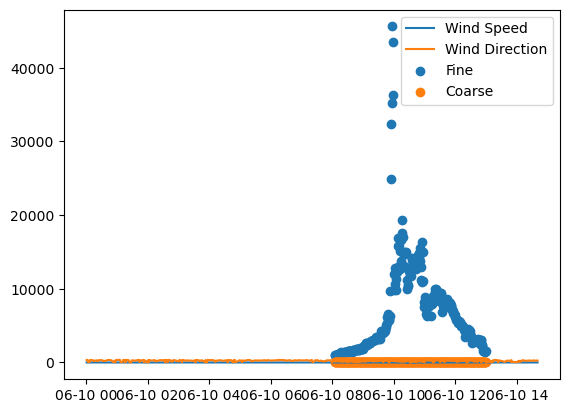

In [15]:


site1 = site1[site1.index >'2025-06-10']
plt.plot(site1.index, site1["speed"], label="Wind Speed")
plt.plot(site1.index, site1['direction'], label="Wind Direction")
plt.scatter(site1.index, site1["Fine"], label="Fine")
plt.scatter(site1.index, site1["Coarse"], label="Coarse")
plt.legend()
plt.show()



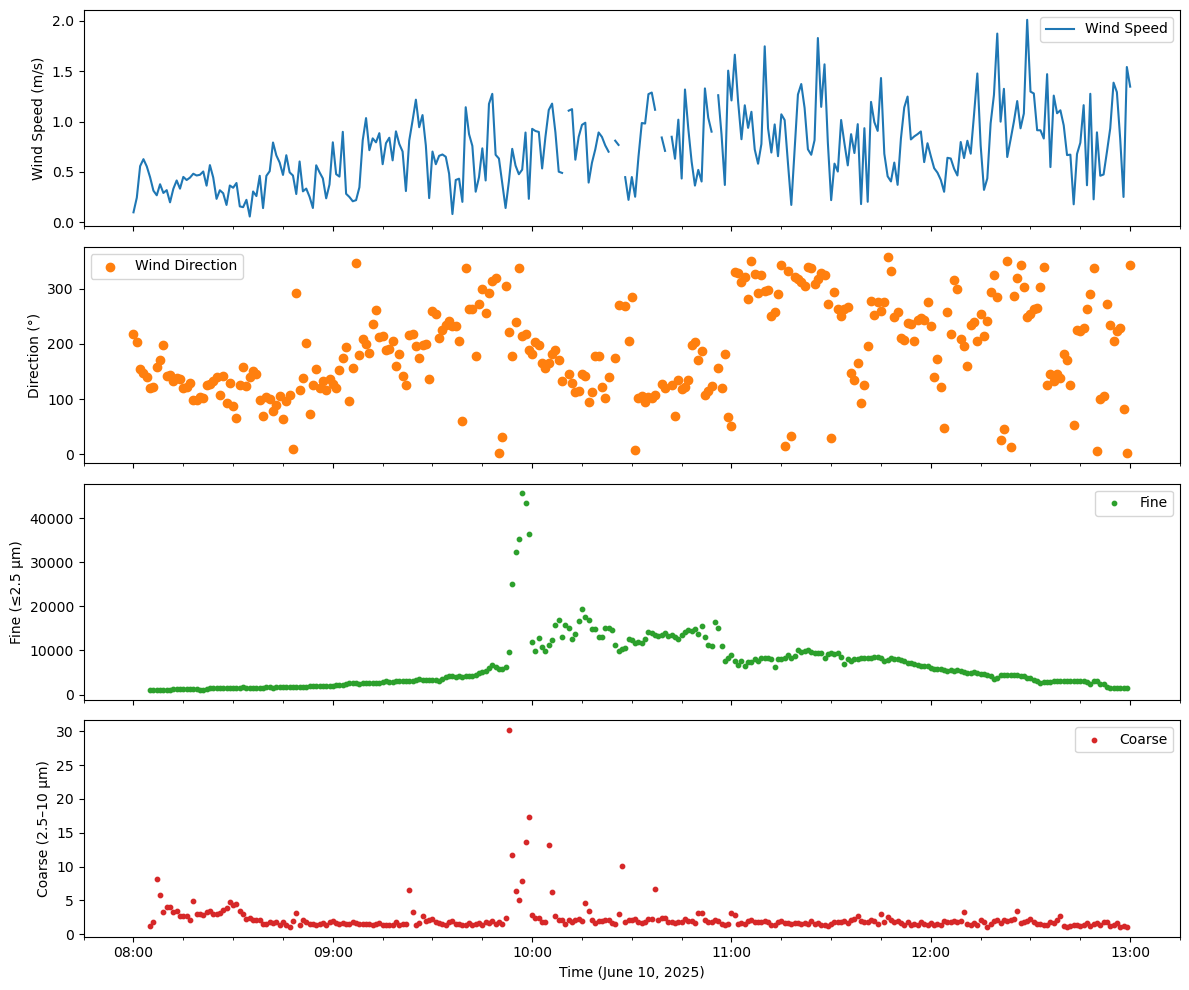

In [66]:
# Filter to June 10, 2025 from 08:00 to 13:00
site1_window = site1.loc["2025-06-10 08:00":"2025-06-10 13:00"]

# Make the 4-panel figure
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

# Wind speed
axes[0].plot(site1_window.index, site1_window["speed"], color="tab:blue")
axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].legend(["Wind Speed"])

# Wind direction
axes[1].scatter(site1_window.index, site1_window["direction"], color="tab:orange")
axes[1].set_ylabel("Direction (°)")
axes[1].legend(["Wind Direction"])
# axes[1].axhspan(30, 150, color="grey", alpha=0.3)

# Fine particles
axes[2].scatter(site1_window.index, site1_window["Fine"], color="tab:green", s=10)
axes[2].set_ylabel("Fine (≤2.5 µm)")
axes[2].legend(["Fine"])

# Coarse particles
axes[3].scatter(site1_window.index, site1_window["Coarse"], color="tab:red", s=10)
axes[3].set_ylabel("Coarse (2.5–10 µm)")
axes[3].legend(["Coarse"])

# Shared x-axis label
time_formatter = mdates.DateFormatter("%H:%M")
axes[3].xaxis.set_major_formatter(time_formatter)
axes[3].xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))
axes[3].set_xlabel("Time (June 10, 2025)")

plt.tight_layout()
plt.show()


In [18]:
# Ensure datetime index and unique for Site1
site2_wind = df_site2_1min.set_index("datetime")
site2_wind = site2_wind[~site2_wind.index.duplicated(keep="first")]

# Ensure datetime index and unique for OPS
dt_1min = dt_1min[~dt_1min.index.duplicated(keep="first")]

# Now safe to concat
site2 = pd.concat([site2_wind, dt_1min], axis=1)

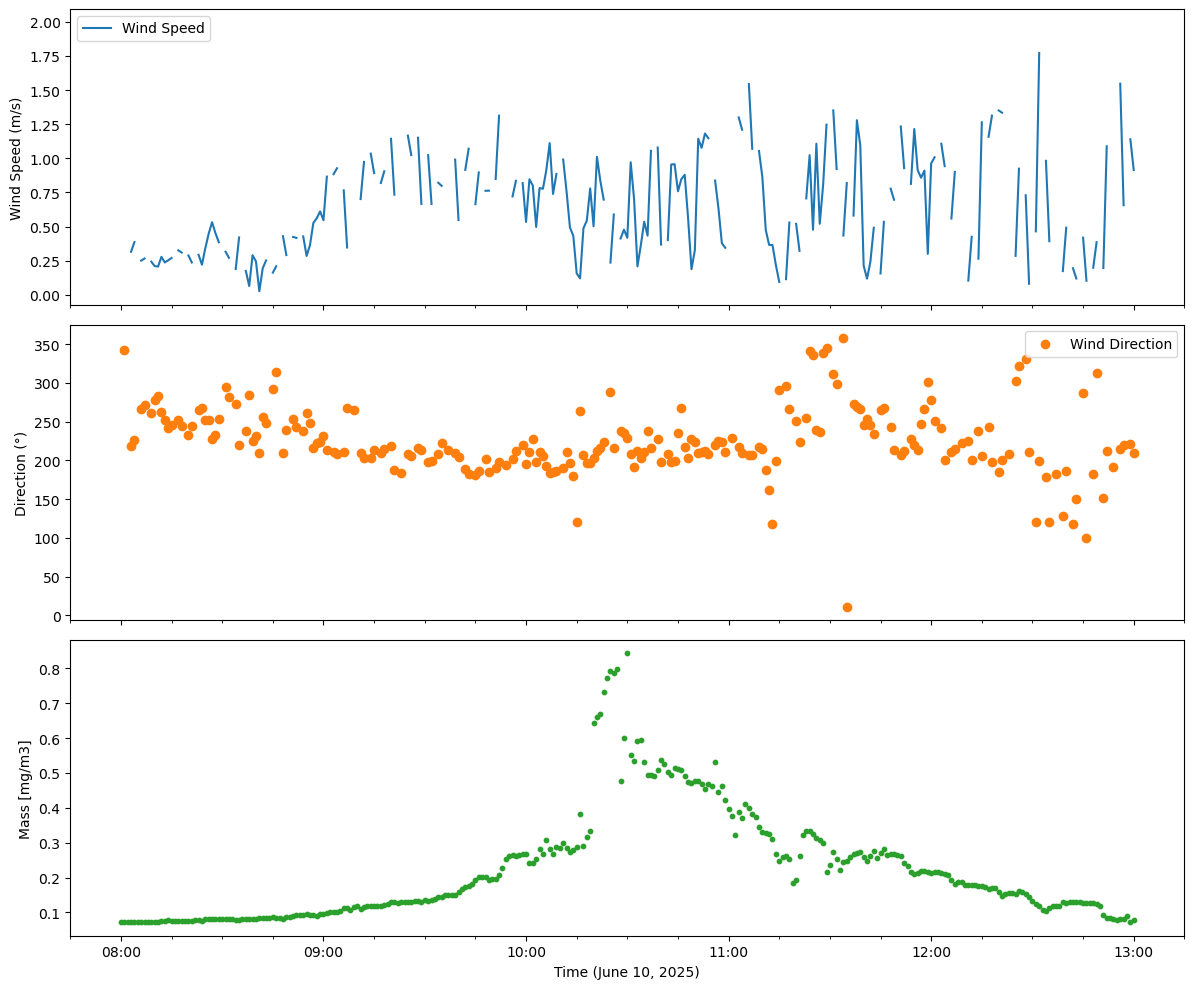

In [65]:
# Filter to June 10, 2025 from 08:00 to 13:00
site2_window = site2.loc["2025-06-10 08:00":"2025-06-10 13:00"]

# Make the 4-panel figure
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Wind speed
axes[0].plot(site2_window.index, site2_window["speed"], color="tab:blue")
axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].legend(["Wind Speed"])

# Wind direction
axes[1].scatter(site2_window.index, site2_window["direction"], color="tab:orange")
axes[1].set_ylabel("Direction (°)")
axes[1].legend(["Wind Direction"])
# axes[1].axhspan(315, 360, color="grey", alpha=0.3)
# axes[1].axhspan(0, 45, color="grey", alpha=0.3)

# DT particles
axes[2].scatter(site2_window.index, site2_window["Mass [mg/m3]"], color="tab:green", s=10)
axes[2].set_ylabel("Mass [mg/m3]")
# axes[2].legend(["Fine"])


# Shared x-axis label
time_formatter = mdates.DateFormatter("%H:%M")
axes[2].xaxis.set_major_formatter(time_formatter)
axes[2].xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))
axes[2].set_xlabel("Time (June 10, 2025)")

plt.tight_layout()
plt.show()


In [25]:
site2_window

,direction,speed,flag_angle,Elapsed Time [s],Mass [mg/m3],Alarms,Errors
datetime,,,,,,,
2025-06-10 08:00:00,NaN,NaN,NaN,1282.5,0.071917,NaN,NaN
2025-06-10 08:01:00,341.856233,0.044599,0.044599,1342.5,0.071917,NaN,NaN
2025-06-10 08:02:00,NaN,NaN,NaN,1402.5,0.072250,NaN,NaN
2025-06-10 08:03:00,218.312599,0.314997,0.314997,1462.5,0.072517,NaN,NaN
2025-06-10 08:04:00,226.230157,0.385597,0.385597,1522.5,0.072667,NaN,NaN
...,...,...,...,...,...,...,...
2025-06-10 12:56:00,214.437962,1.547205,1.547205,19042.5,0.080550,NaN,NaN
2025-06-10 12:57:00,219.862268,0.656093,0.656093,19102.5,0.080250,NaN,NaN
2025-06-10 12:58:00,NaN,NaN,NaN,19162.5,0.088500,NaN,NaN


In [47]:
ops_1min

,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Unnamed: 24,Fine,Coarse
datetime,,,,,,,,,,,,,,,,,,,,,
2025-06-10 08:05:00,603.5,768.166667,199.666667,32.833333,7.833333,3.500000,4.000000,1.833333,1.333333,1.500000,...,0.000000,0.000000,0.005746,29.581833,0.0,96.920000,NaN,NaN,1021.000000,1.166667
2025-06-10 08:06:00,636.5,754.366667,197.350000,31.766667,7.683333,2.433333,4.483333,1.516667,1.616667,1.383333,...,0.050000,0.033333,0.005668,29.696700,0.0,96.930333,NaN,NaN,1003.383333,1.866667
2025-06-10 08:07:00,696.5,771.100000,203.350000,34.116667,7.633333,3.016667,4.983333,1.600000,2.333333,2.416667,...,0.700000,0.583333,0.005944,29.915833,0.0,96.926717,NaN,NaN,1032.683333,8.166667
2025-06-10 08:08:00,756.5,759.950000,197.750000,34.150000,8.516667,2.983333,5.150000,1.950000,2.083333,2.050000,...,0.550000,0.333333,0.005820,30.141283,0.0,96.933950,NaN,NaN,1016.633333,5.800000
2025-06-10 08:09:00,816.5,785.966667,205.650000,34.133333,8.733333,3.033333,4.566667,1.283333,1.833333,1.483333,...,0.216667,0.116667,0.005925,30.351217,0.0,96.935500,NaN,NaN,1047.916667,3.233333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-10 12:55:00,17976.5,1185.400000,274.966667,50.500000,13.400000,3.850000,6.316667,1.916667,2.200000,1.716667,...,0.033333,0.033333,0.008398,53.771483,0.0,96.857000,NaN,NaN,1541.033333,1.300000
2025-06-10 12:56:00,18036.5,1201.100000,280.366667,51.566667,13.750000,3.600000,6.133333,1.450000,1.766667,1.533333,...,0.000000,0.016667,0.008503,53.798067,0.0,96.857517,NaN,NaN,1562.133333,1.600000
2025-06-10 12:57:00,18096.5,1137.250000,268.050000,49.616667,11.833333,3.750000,6.633333,1.666667,1.983333,1.216667,...,0.000000,0.033333,0.008085,53.814250,0.0,96.857000,NaN,NaN,1483.033333,1.133333


In [ ]:
# Define windows of interest
pre_start, pre_end   = "2025-06-10 08:05", "2025-06-10 08:35"
burn_start, burn_end = "2025-06-10 09:45", "2025-06-10 10:15"
post_start, post_end = "2025-06-10 12:30", "2025-06-10 13:00"




In [57]:
pre = ops_1min.loc[pre_start:pre_end]
burn = ops_1min.loc[burn_start:burn_end]
post = ops_1min.loc[post_start: post_end]


In [58]:
pre["Phase"]  = "Pre-burn"
burn["Phase"] = "Burn"
post["Phase"] = "Post-burn"

# Combine
ops_phases = pd.concat([pre, burn, post])

C:\Users\bmaro\AppData\Local\Temp\ipykernel_5168\18857219.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pre["Phase"]  = "Pre-burn"
C:\Users\bmaro\AppData\Local\Temp\ipykernel_5168\18857219.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  burn["Phase"] = "Burn"
C:\Users\bmaro\AppData\Local\Temp\ipykernel_5168\18857219.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

In [59]:
ops_long = ops_phases.melt(
    id_vars="Phase",
    value_vars=[col for col in ops_phases.columns if "Bin" in col],
    var_name="Bin",
    value_name="Concentration"
)


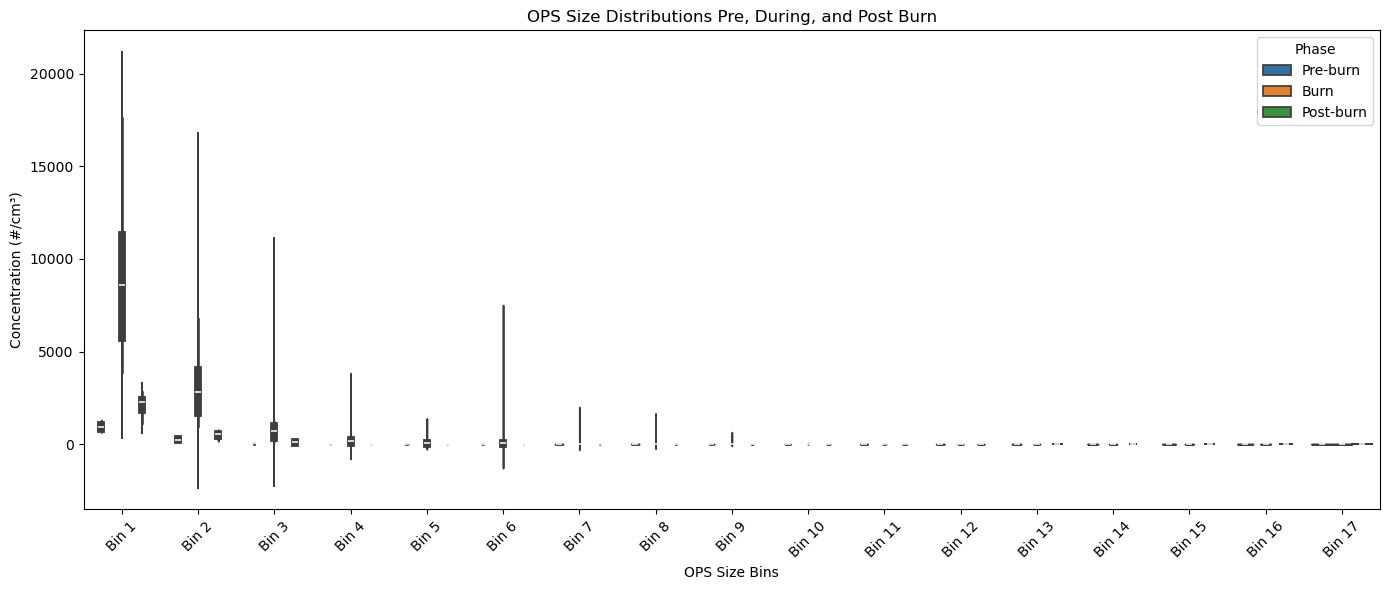

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
sns.violinplot(data=ops_long, x="Bin", y="Concentration", hue="Phase", split=False)

plt.xticks(rotation=45)
plt.ylabel("Concentration (#/cm³)")
plt.xlabel("OPS Size Bins")
plt.title("OPS Size Distributions Pre, During, and Post Burn")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()


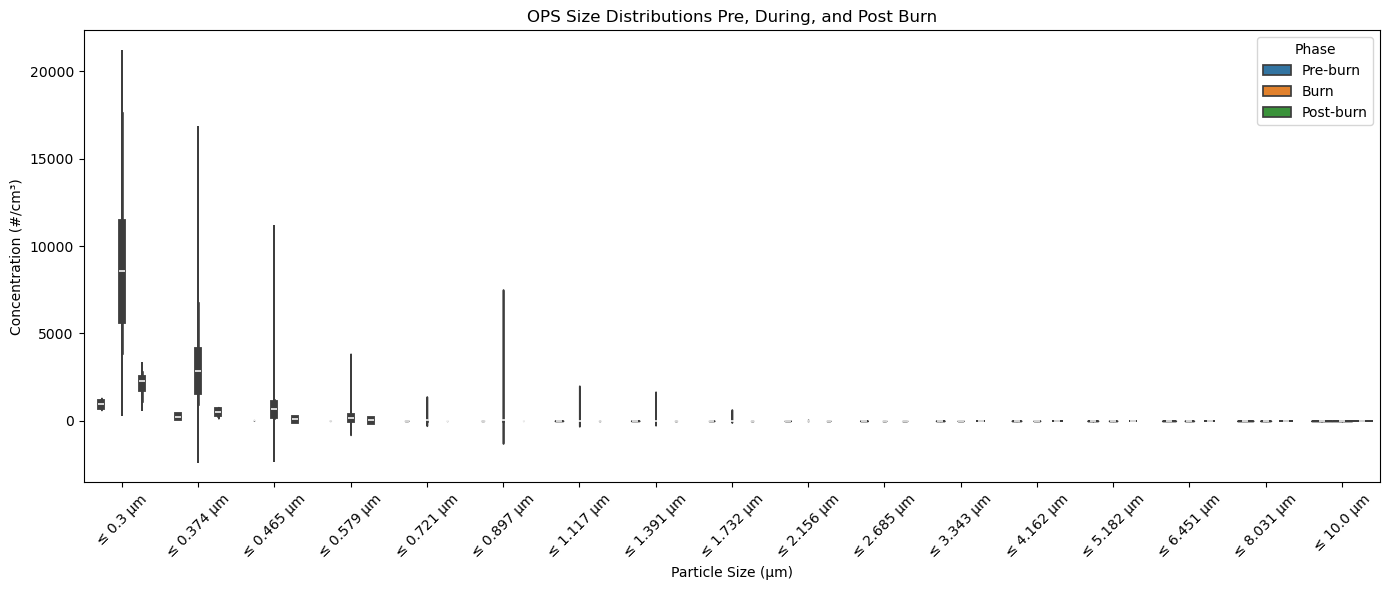

In [61]:
bin_edges = meta["Bin Cut Points"]  # dict {bin_number: cutoff_um}
# Create a mapping from "Bin N" → "≤ X µm"
bin_map = {f"Bin {b}": f"≤ {edge} µm" for b, edge in sorted(bin_edges.items())}

ops_long["Bin"] = ops_long["Bin"].map(bin_map)

plt.figure(figsize=(14,6))
sns.violinplot(data=ops_long, x="Bin", y="Concentration", hue="Phase", split=False)

plt.xticks(rotation=45)
plt.ylabel("Concentration (#/cm³)")
plt.xlabel("Particle Size (µm)")
plt.title("OPS Size Distributions Pre, During, and Post Burn")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()


In [63]:
ops_long["Group"] = ops_long["Bin"].map(lambda x: "Fine (≤2.5µm)" if "≤" in x and float(x.split()[1]) <= 2.5 else "Coarse (2.5–10µm)")
means = ops_long.groupby(["Phase","Bin"]).mean().reset_index()
sns.barplot(data=means, x="Bin", y="Concentration", hue="Phase")



TypeError: agg function failed [how->mean,dtype->object]

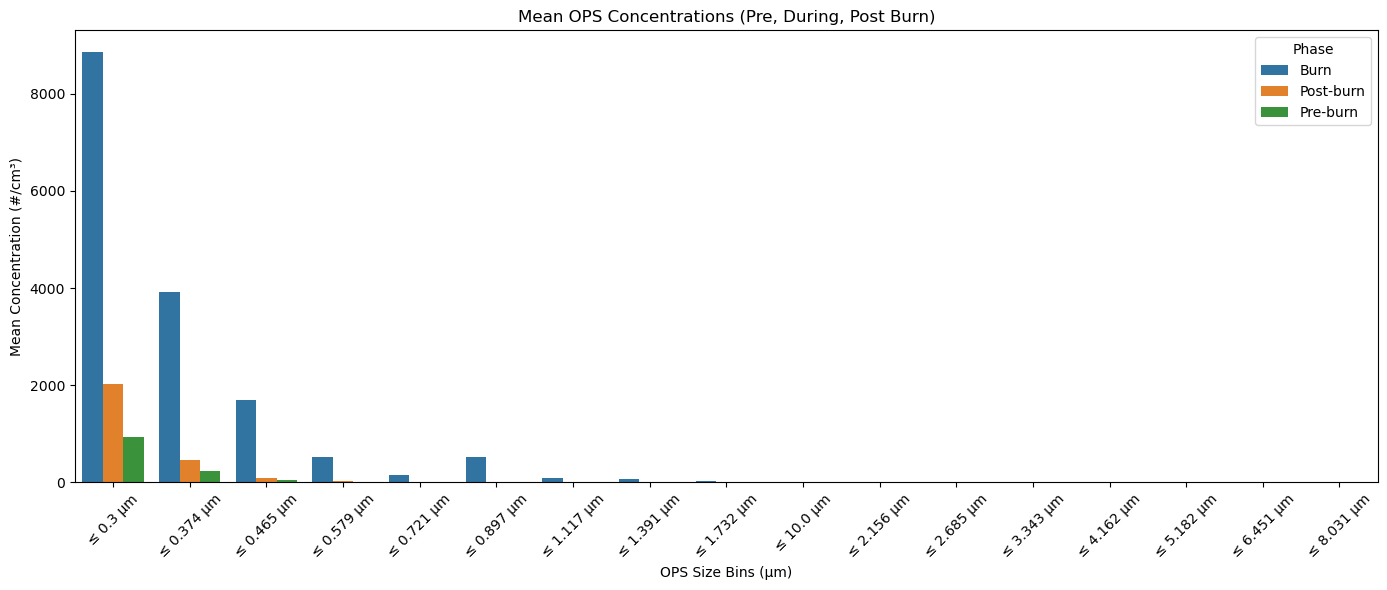

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

phase_order = ['Pre-burn', 'Burn', 'Post-burn']

means = ops_long.groupby(["Phase","Bin"]).mean(numeric_only=True).reset_index()
means = ops_long.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()

# compute means safely
means = ops_long.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()


plt.figure(figsize=(14,6))
sns.barplot(data=means, x="Bin", y="Concentration", hue="Phase")

plt.xticks(rotation=45)
plt.ylabel("Mean Concentration (#/cm³)")
plt.xlabel("OPS Size Bins (µm)")
plt.title("Mean OPS Concentrations (Pre, During, Post Burn)")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()


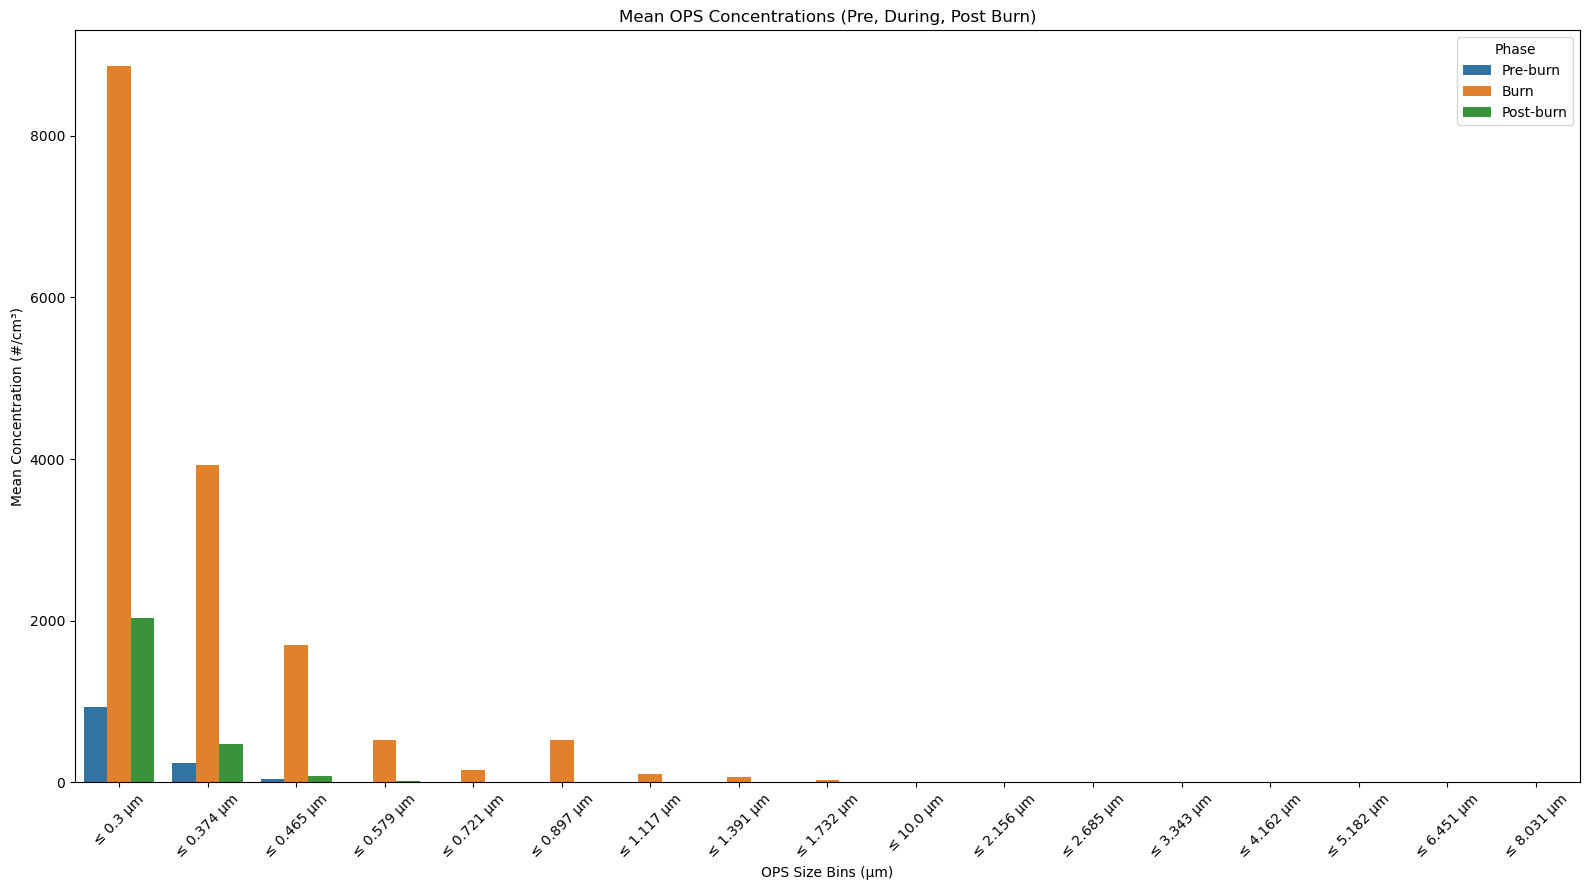

In [ ]:
means = ops_long.groupby(["Phase","Bin"]).mean(numeric_only=True).reset_index()
means = ops_long.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()


# compute means safely
means = ops_long.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()
means_sorted = means.sort_values('Bin')

plt.figure(figsize=(16,9))

hue_order = ['Pre-burn', 'Burn', 'Post-burn']

# Create the bar plot with the specified hue_order
sns.barplot(data=means_sorted, x="Bin", y="Concentration", hue="Phase", hue_order=hue_order)


plt.xticks(rotation=45)
plt.ylabel("Mean Concentration (#/cm³)")
plt.xlabel("OPS Size Bins (µm)")
plt.title("Mean OPS Concentrations (Pre, During, Post Burn)")

plt.legend(title="Phase")
plt.tight_layout()
plt.show()


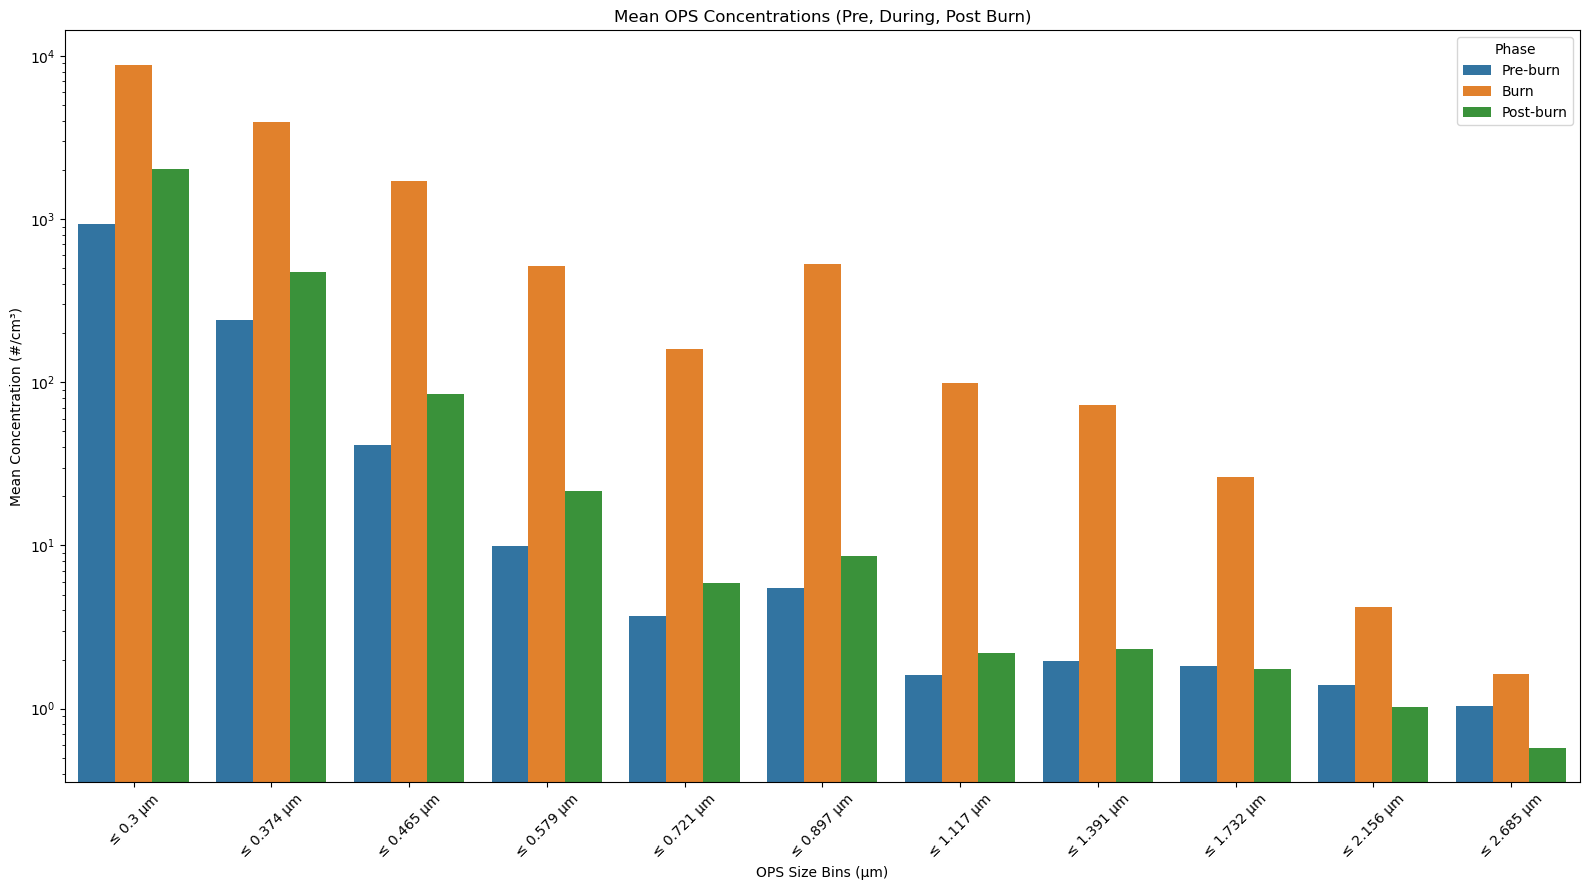

In [78]:
pm25_bins = ['≤ 0.3 µm', '≤ 0.374 µm', '≤ 0.465 µm', '≤ 0.579 µm', '≤ 0.721 µm',
       '≤ 0.897 µm', '≤ 1.117 µm', '≤ 1.391 µm', '≤ 1.732 µm',
        '≤ 2.156 µm', '≤ 2.685 µm']
ops_25 = ops_long[ops_long['Bin'].isin(pm25_bins)]

means = ops_25.groupby(["Phase","Bin"]).mean(numeric_only=True).reset_index()
means = ops_25.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()


# compute means safely
means = ops_25.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()
means_sorted = means.sort_values('Bin')

plt.figure(figsize=(16,9))

hue_order = ['Pre-burn', 'Burn', 'Post-burn']

# Create the bar plot with the specified hue_order
sns.barplot(data=means_sorted, x="Bin", y="Concentration", hue="Phase", hue_order=hue_order)


plt.xticks(rotation=45)
plt.ylabel("Mean Concentration (#/cm³)")
plt.xlabel("OPS Size Bins (µm)")
plt.yscale('log')
plt.title("Mean OPS Concentrations (Pre, During, Post Burn)")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()


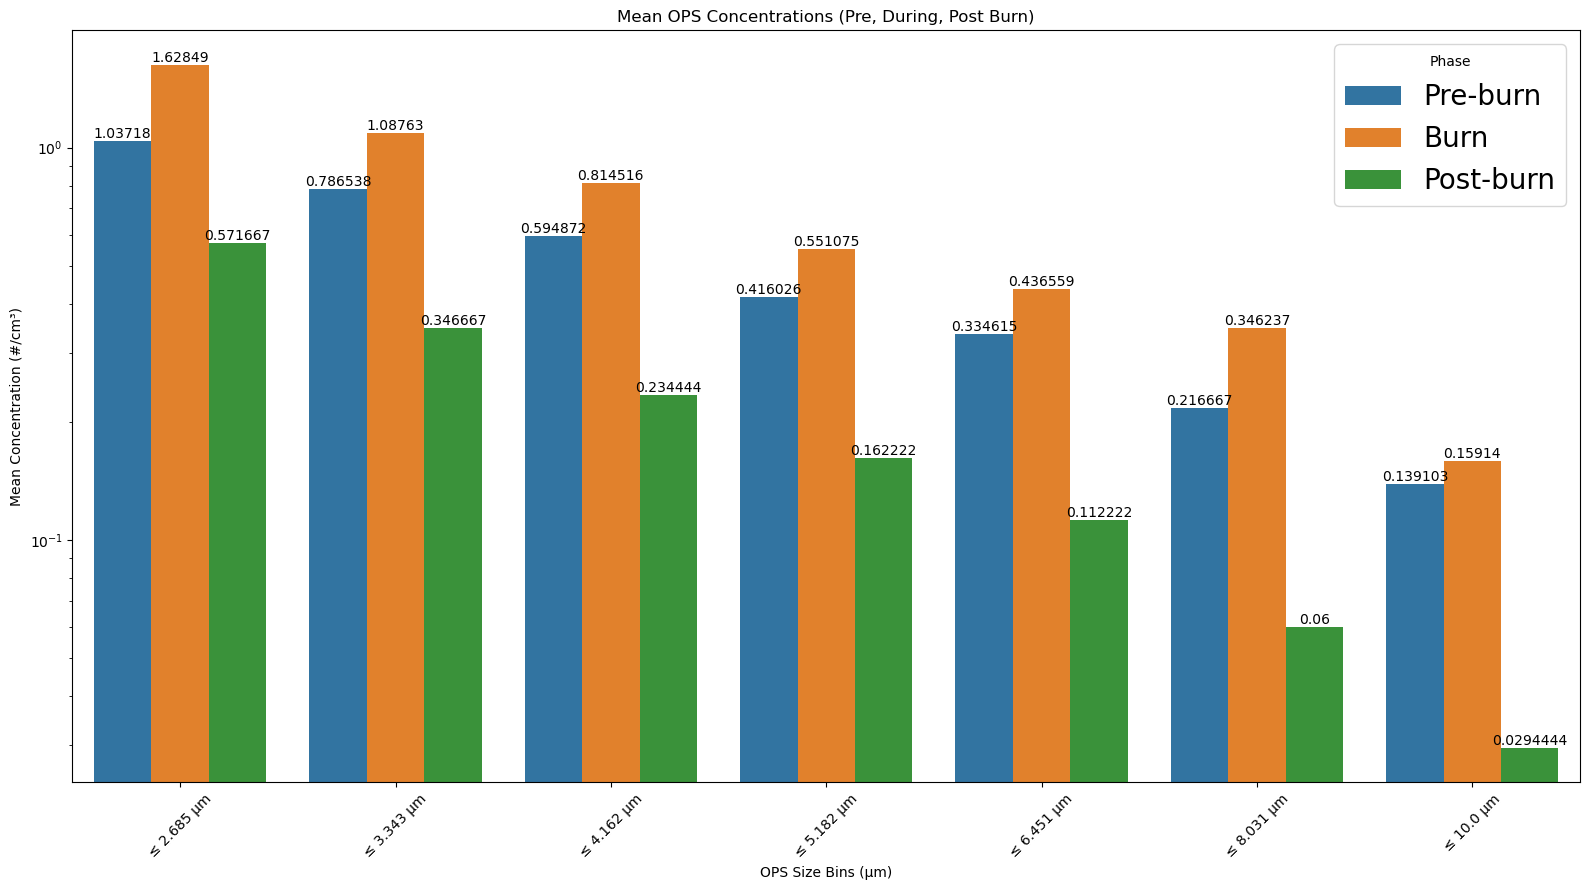

In [89]:
pm25_bins = ['≤ 0.3 µm', '≤ 0.374 µm', '≤ 0.465 µm', '≤ 0.579 µm', '≤ 0.721 µm',
       '≤ 0.897 µm', '≤ 1.117 µm', '≤ 1.391 µm', '≤ 1.732 µm',
        '≤ 2.156 µm', '≤ 2.685 µm']
pm10_bins = ['≤ 2.685 µm', '≤ 3.343 µm',
       '≤ 4.162 µm', '≤ 5.182 µm', '≤ 6.451 µm', '≤ 8.031 µm', '≤ 10.0 µm']
ops_10 = ops_long[ops_long['Bin'].isin(pm10_bins)]
# ops_10 = ops_long[~ops_long['Bin'].isin(pm25_bins)]


means = ops_10.groupby(["Phase","Bin"]).mean(numeric_only=True).reset_index()
means = ops_10.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()


# compute means safely
means = ops_10.groupby(["Phase","Bin"])["Concentration"].mean().reset_index()
means_sorted = means.sort_values('Bin')

plt.figure(figsize=(16,9))

hue_order = ['Pre-burn', 'Burn', 'Post-burn']

custom_order = ['≤ 2.685 µm', '≤ 3.343 µm',
       '≤ 4.162 µm', '≤ 5.182 µm', '≤ 6.451 µm', '≤ 8.031 µm', '≤ 10.0 µm']
# Create the bar plot with the specified hue_order
ax = sns.barplot(data=means_sorted, x="Bin", y="Concentration", hue="Phase", hue_order=hue_order, order = custom_order)
for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=45)
plt.ylabel("Mean Concentration (#/cm³)")
plt.xlabel("OPS Size Bins (µm)")
plt.yscale('log')
plt.title("Mean OPS Concentrations (Pre, During, Post Burn)")
plt.legend(title="Phase", fontsize=20)
plt.tight_layout()
plt.show()


In [76]:
means['Bin'].unique()

array(['≤ 0.3 µm', '≤ 0.374 µm', '≤ 0.465 µm', '≤ 0.579 µm', '≤ 0.721 µm',
       '≤ 0.897 µm', '≤ 1.117 µm', '≤ 1.391 µm', '≤ 1.732 µm',
       '≤ 10.0 µm', '≤ 2.156 µm', '≤ 2.685 µm', '≤ 3.343 µm',
       '≤ 4.162 µm', '≤ 5.182 µm', '≤ 6.451 µm', '≤ 8.031 µm'],
      dtype=object)